In [2]:
import pandas as pd

df_iris = pd.read_csv('IRIS.csv')
df_iris

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica


In [3]:
from sklearn.model_selection import train_test_split

x = df_iris.drop('species', axis=1)
y = df_iris['species']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [4]:
from sklearn.tree import DecisionTreeClassifier

clf = DecisionTreeClassifier(max_depth=3)
clf.fit(x_train, y_train)

DecisionTreeClassifier(max_depth=3)

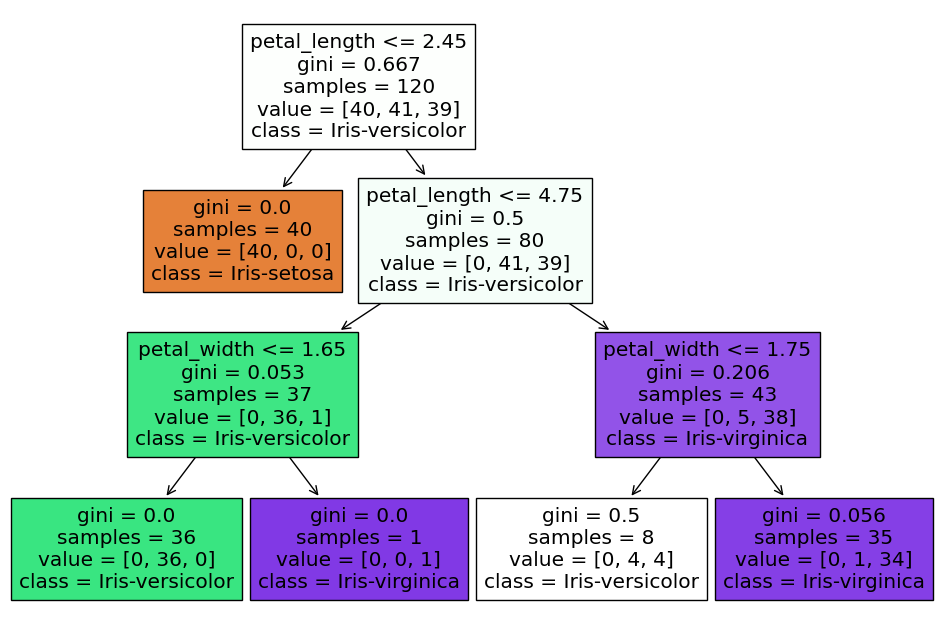

In [6]:
from sklearn import tree
import matplotlib.pyplot as plt

plt.figure(figsize=(12,8))
tree.plot_tree(clf, feature_names=x.columns, class_names=clf.classes_, filled=True)
plt.show()

In [8]:
from sklearn.metrics import accuracy_score, confusion_matrix

y_pred = clf.predict(x_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred)}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 1.0
Confusion Matrix:
[[10  0  0]
 [ 0  9  0]
 [ 0  0 11]]


In [3]:
import pandas as pd
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing()
df_housing = pd.DataFrame(housing.data, columns=housing.feature_names)
df_housing['MedHouseVal'] = housing.target

df_housing.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
from sklearn.model_selection import train_test_split

X = df_housing.drop('MedHouseVal', axis=1)
y = df_housing['MedHouseVal']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [5]:
from sklearn.model_selection import GridSearchCV
from sklearn.tree import DecisionTreeRegressor

# Define the range of depths you want to test
#param_grid = {'max_depth': [3, 5, 10, 15, 20, None]}
param_grid = {
    'max_depth': list(range(5, 15)) + [None] 
}

# Use GridSearch to find the best one
grid_search = GridSearchCV(DecisionTreeRegressor(), param_grid, cv=5)
grid_search.fit(X_train, y_train)

print(f"Best Depth: {grid_search.best_params_}")

Best Depth: {'max_depth': 9}


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Use the best model from your grid search to make predictions
best_tree = grid_search.best_estimator_
y_pred = best_tree.predict(X_test)

# Calculate Metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R^2 Score: {r2:.4f}")

Mean Absolute Error (MAE): 0.4344
Root Mean Squared Error (RMSE): 0.6385
R^2 Score: 0.6889


In [7]:
train_score = best_tree.score(X_train, y_train)
test_score = best_tree.score(X_test, y_test)

print(f"Training R2: {train_score:.4f}")
print(f"Test R2: {test_score:.4f}")

Training R2: 0.7999
Test R2: 0.6889


In [8]:
#param_grid = {
#    'max_depth': [8, 9, 10], # We know 9 is around the sweet spot
#    'min_samples_split': [20, 50, 100], 
#    'min_samples_leaf': [10, 20, 40]
#}

#refined grid based on above
param_grid = {
    'max_depth': [10, 11, 12, 13], 
    'min_samples_split': [40, 50, 60, 70],
    'min_samples_leaf': [15, 20, 25, 30]
}

grid_search = GridSearchCV(DecisionTreeRegressor(random_state=42), param_grid, cv=5)
grid_search.fit(X_train, y_train)

print(f"New Best Params: {grid_search.best_params_}")

New Best Params: {'max_depth': 13, 'min_samples_leaf': 15, 'min_samples_split': 50}


In [9]:
# Use the best model from your grid search to make predictions
best_tree = grid_search.best_estimator_
y_pred = best_tree.predict(X_test)

# Calculate Metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R^2 Score: {r2:.4f}")

Mean Absolute Error (MAE): 0.4035
Root Mean Squared Error (RMSE): 0.5995
R^2 Score: 0.7257


In [10]:
train_score = best_tree.score(X_train, y_train)
test_score = best_tree.score(X_test, y_test)

print(f"Training R2: {train_score:.4f}")
print(f"Test R2: {test_score:.4f}")

Training R2: 0.8083
Test R2: 0.7257


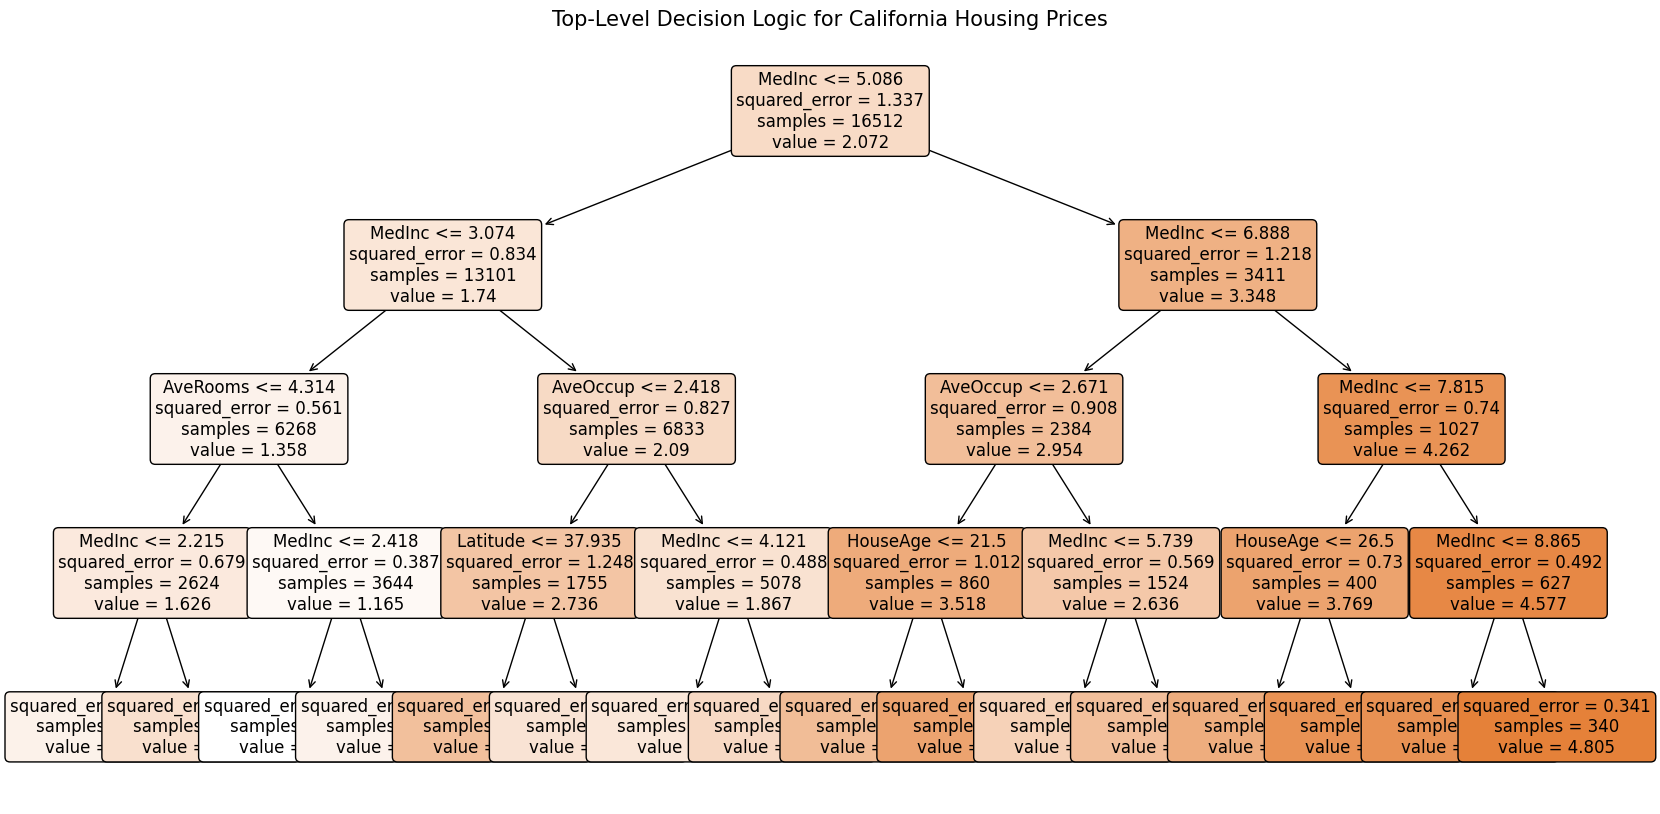

In [11]:
from sklearn import tree
import matplotlib.pyplot as plt

# We create a "visual" version of your best model limited to depth 3 
# so we can actually read the nodes.
visual_tree = DecisionTreeRegressor(max_depth=4, 
                                    min_samples_leaf=15, 
                                    random_state=42)
visual_tree.fit(X_train, y_train)

plt.figure(figsize=(20,10))
tree.plot_tree(visual_tree, 
               feature_names=X.columns, 
               filled=True, 
               rounded=True, 
               fontsize=12)
plt.title("Top-Level Decision Logic for California Housing Prices", fontsize=15)
plt.show()

In [12]:
from sklearn.tree import export_text

# Use your 'best_model' or 'visual_tree'
tree_rules = export_text(visual_tree, feature_names=list(X.columns))

print(tree_rules)

|--- MedInc <= 5.09
|   |--- MedInc <= 3.07
|   |   |--- AveRooms <= 4.31
|   |   |   |--- MedInc <= 2.21
|   |   |   |   |--- value: [1.38]
|   |   |   |--- MedInc >  2.21
|   |   |   |   |--- value: [1.91]
|   |   |--- AveRooms >  4.31
|   |   |   |--- MedInc <= 2.42
|   |   |   |   |--- value: [0.97]
|   |   |   |--- MedInc >  2.42
|   |   |   |   |--- value: [1.36]
|   |--- MedInc >  3.07
|   |   |--- AveOccup <= 2.42
|   |   |   |--- Latitude <= 37.93
|   |   |   |   |--- value: [2.89]
|   |   |   |--- Latitude >  37.93
|   |   |   |   |--- value: [1.81]
|   |   |--- AveOccup >  2.42
|   |   |   |--- MedInc <= 4.12
|   |   |   |   |--- value: [1.70]
|   |   |   |--- MedInc >  4.12
|   |   |   |   |--- value: [2.11]
|--- MedInc >  5.09
|   |--- MedInc <= 6.89
|   |   |--- AveOccup <= 2.67
|   |   |   |--- HouseAge <= 21.50
|   |   |   |   |--- value: [2.98]
|   |   |   |--- HouseAge >  21.50
|   |   |   |   |--- value: [3.76]
|   |   |--- AveOccup >  2.67
|   |   |   |--- MedInc <=

In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Load from a URL (common source for this dataset)
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
names = ['preg', 'plas', 'pres', 'skin', 'test', 'mass', 'pedi', 'age', 'class']
df_pima = pd.read_csv(url, names=names)

X = df_pima.drop('class', axis=1)
y = df_pima['class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

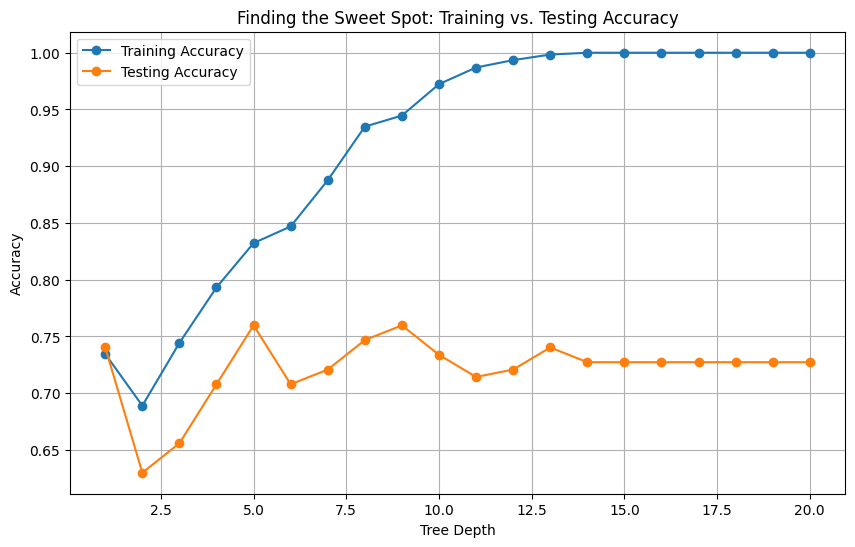

In [14]:
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt

train_scores = []
test_scores = []
depths = range(1, 21)

for d in depths:
    # 'balanced' helps with the 65/35 split in this data
    clf = DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=42)
    clf.fit(X_train, y_train)
    
    train_scores.append(clf.score(X_train, y_train))
    test_scores.append(clf.score(X_test, y_test))

# Plotting the Tradeoff
plt.figure(figsize=(10, 6))
plt.plot(depths, train_scores, label='Training Accuracy', marker='o')
plt.plot(depths, test_scores, label='Testing Accuracy', marker='o')
plt.xlabel('Tree Depth')
plt.ylabel('Accuracy')
plt.title('Finding the Sweet Spot: Training vs. Testing Accuracy')
plt.legend()
plt.grid(True)
plt.show()

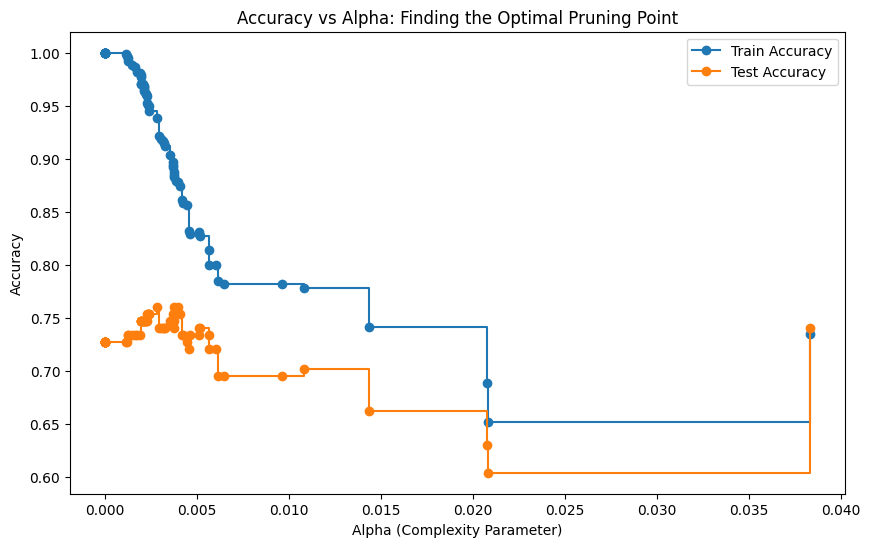

In [16]:
clfs = []
# We iterate through all alphas to see the full "thinning" of the tree
for ccp_alpha in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=42, ccp_alpha=ccp_alpha, class_weight='balanced')
    clf.fit(X_train, y_train)
    clfs.append(clf)

# Remove the last tree because it's just a single root node (useless for prediction)
clfs = clfs[:-1]
ccp_alphas_plot = ccp_alphas[:-1]

# Calculate scores
train_scores = [clf.score(X_train, y_train) for clf in clfs]
test_scores = [clf.score(X_test, y_test) for clf in clfs]

# Plotting the results
plt.figure(figsize=(10, 6))
plt.plot(ccp_alphas_plot, train_scores, marker='o', label="Train Accuracy", drawstyle="steps-post")
plt.plot(ccp_alphas_plot, test_scores, marker='o', label="Test Accuracy", drawstyle="steps-post")
plt.xlabel("Alpha (Complexity Parameter)")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Alpha: Finding the Optimal Pruning Point")
plt.legend()
plt.show()

In [17]:
# Create a dataframe to easily find the max
import pandas as pd
perf_df = pd.DataFrame({'alpha': ccp_alphas_plot, 'test_score': test_scores})

# Find the alpha with the highest test score
best_alpha = perf_df.sort_values(by='test_score', ascending=False).iloc[0]['alpha']
print(f"The mathematically best alpha is: {best_alpha}")

The mathematically best alpha is: 0.003737599105213172


In [18]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import seaborn as sns

# Initialize with your best alpha
final_clf = DecisionTreeClassifier(random_state=42, 
                                   ccp_alpha=0.0037, 
                                   class_weight='balanced')
final_clf.fit(X_train, y_train)

# Make predictions
y_pred = final_clf.predict(X_test)

In [19]:
print(f"Final Accuracy: {accuracy_score(y_test, y_pred):.4f}")
print("-" * 30)
print(classification_report(y_test, y_pred))

Final Accuracy: 0.7532
------------------------------
              precision    recall  f1-score   support

           0       0.88      0.72      0.79        99
           1       0.62      0.82      0.70        55

    accuracy                           0.75       154
   macro avg       0.75      0.77      0.75       154
weighted avg       0.78      0.75      0.76       154



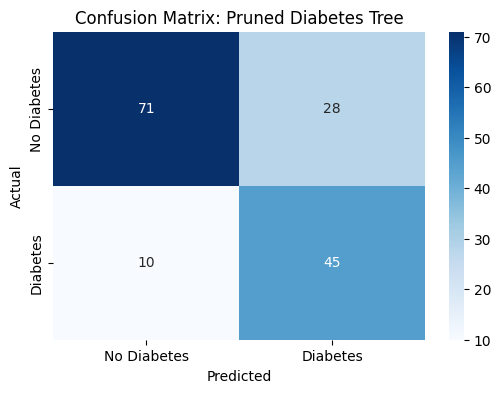

In [20]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['No Diabetes', 'Diabetes'], 
            yticklabels=['No Diabetes', 'Diabetes'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix: Pruned Diabetes Tree')
plt.show()

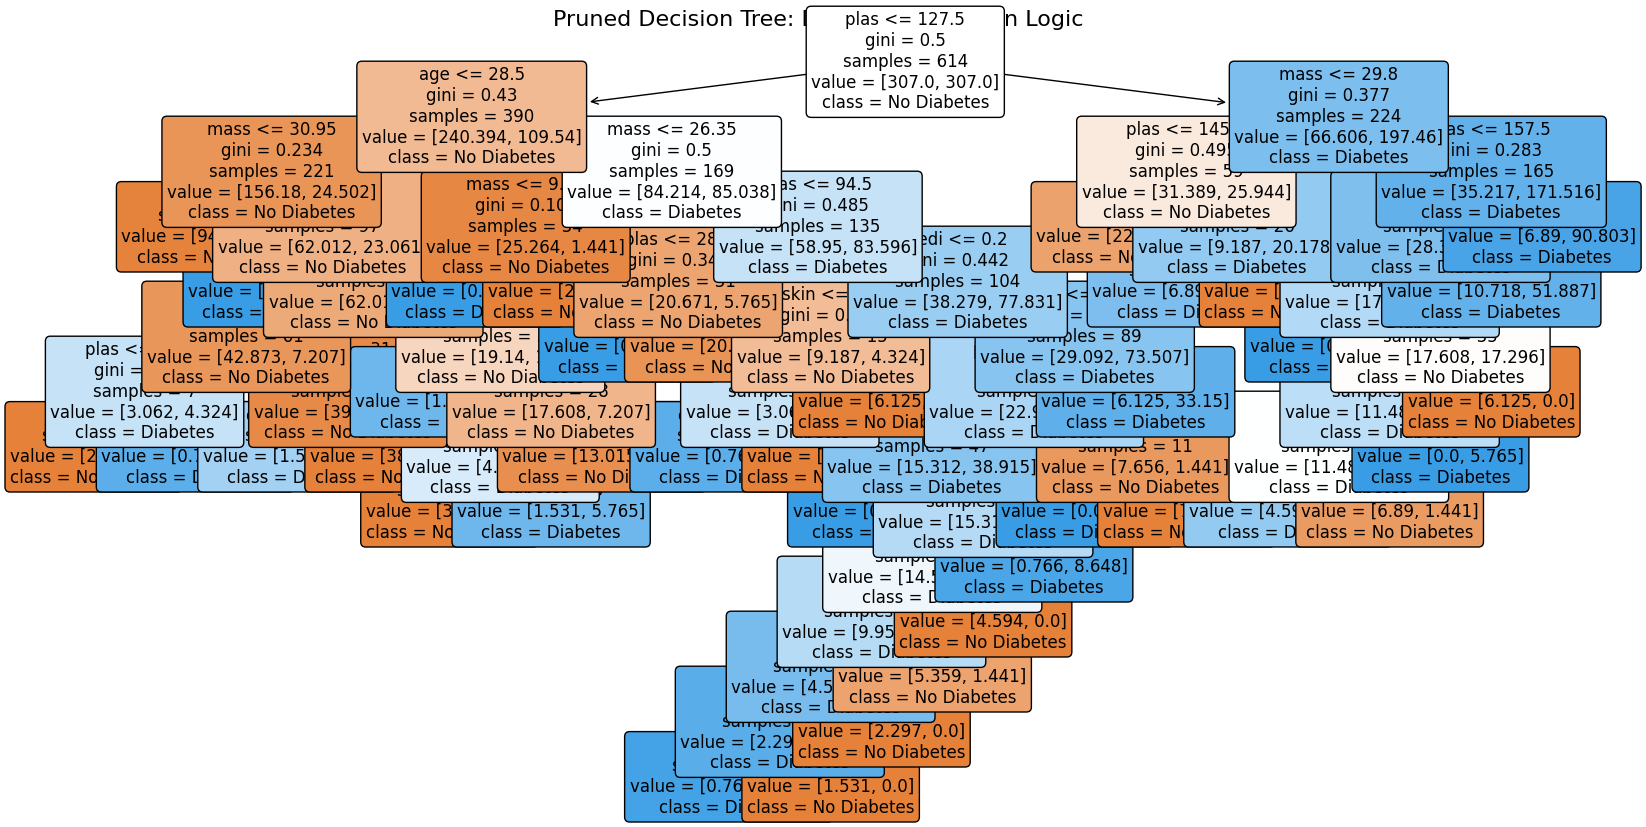

In [21]:
from sklearn import tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20,10))
tree.plot_tree(final_clf, 
               feature_names=list(X.columns), 
               class_names=['No Diabetes', 'Diabetes'], 
               filled=True, 
               rounded=True, 
               fontsize=12)
plt.title("Pruned Decision Tree: Diabetes Prediction Logic", fontsize=16)
plt.show()

In [22]:
from sklearn.tree import export_text

# Generate the text rules
rules = export_text(final_clf, feature_names=list(X.columns))

print("--- Decision Tree Rules ---")
print(rules)

--- Decision Tree Rules ---
|--- plas <= 127.50
|   |--- age <= 28.50
|   |   |--- mass <= 30.95
|   |   |   |--- class: 0
|   |   |--- mass >  30.95
|   |   |   |--- pres <= 37.00
|   |   |   |   |--- class: 1
|   |   |   |--- pres >  37.00
|   |   |   |   |--- pedi <= 0.50
|   |   |   |   |   |--- skin <= 8.50
|   |   |   |   |   |   |--- plas <= 109.50
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |   |--- plas >  109.50
|   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- skin >  8.50
|   |   |   |   |   |   |--- mass <= 31.80
|   |   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |   |--- mass >  31.80
|   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |--- pedi >  0.50
|   |   |   |   |   |--- pedi <= 0.54
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- pedi >  0.54
|   |   |   |   |   |   |--- pres <= 67.00
|   |   |   |   |   |   |   |--- test <= 70.00
|   |   |   |   |   |   |   |   |--- class: 0
|   |   |   |   |   | 

In [2]:
# The dataset is large, so we fetch it directly
import pandas as pd
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"
df_fraud = pd.read_csv(url)

# Take a look at the class distribution
print(df_fraud['Class'].value_counts())
print(f"\nFraud Percentage: {df_fraud['Class'].mean()*100:.4f}%")

Class
0    284315
1       492
Name: count, dtype: int64

Fraud Percentage: 0.1727%


In [3]:
from sklearn.model_selection import train_test_split

X = df_fraud.drop(['Class', 'Time'], axis=1) # Time is usually just a sequence, not a feature
y = df_fraud['Class']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [5]:
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier

depths = range(3, 8)
results = []

for d in depths:
    # Train model
    temp_tree = DecisionTreeClassifier(max_depth=d, class_weight='balanced', random_state=42)
    temp_tree.fit(X_train, y_train)
    
    # Predict
    y_pred = temp_tree.predict(X_test)
    
    # Calculate Metrics for the 'Fraud' class (Class 1)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    
    results.append({'Depth': d, 'Precision': prec, 'Recall': rec, 'F1-Score': f1})

# Display the results as a table
df_results = pd.DataFrame(results)
print(df_results)

   Depth  Precision    Recall  F1-Score
0      3   0.033449  0.887755  0.064468
1      4   0.030453  0.877551  0.058864
2      5   0.047383  0.877551  0.089911
3      6   0.059691  0.867347  0.111695
4      7   0.059238  0.857143  0.110818


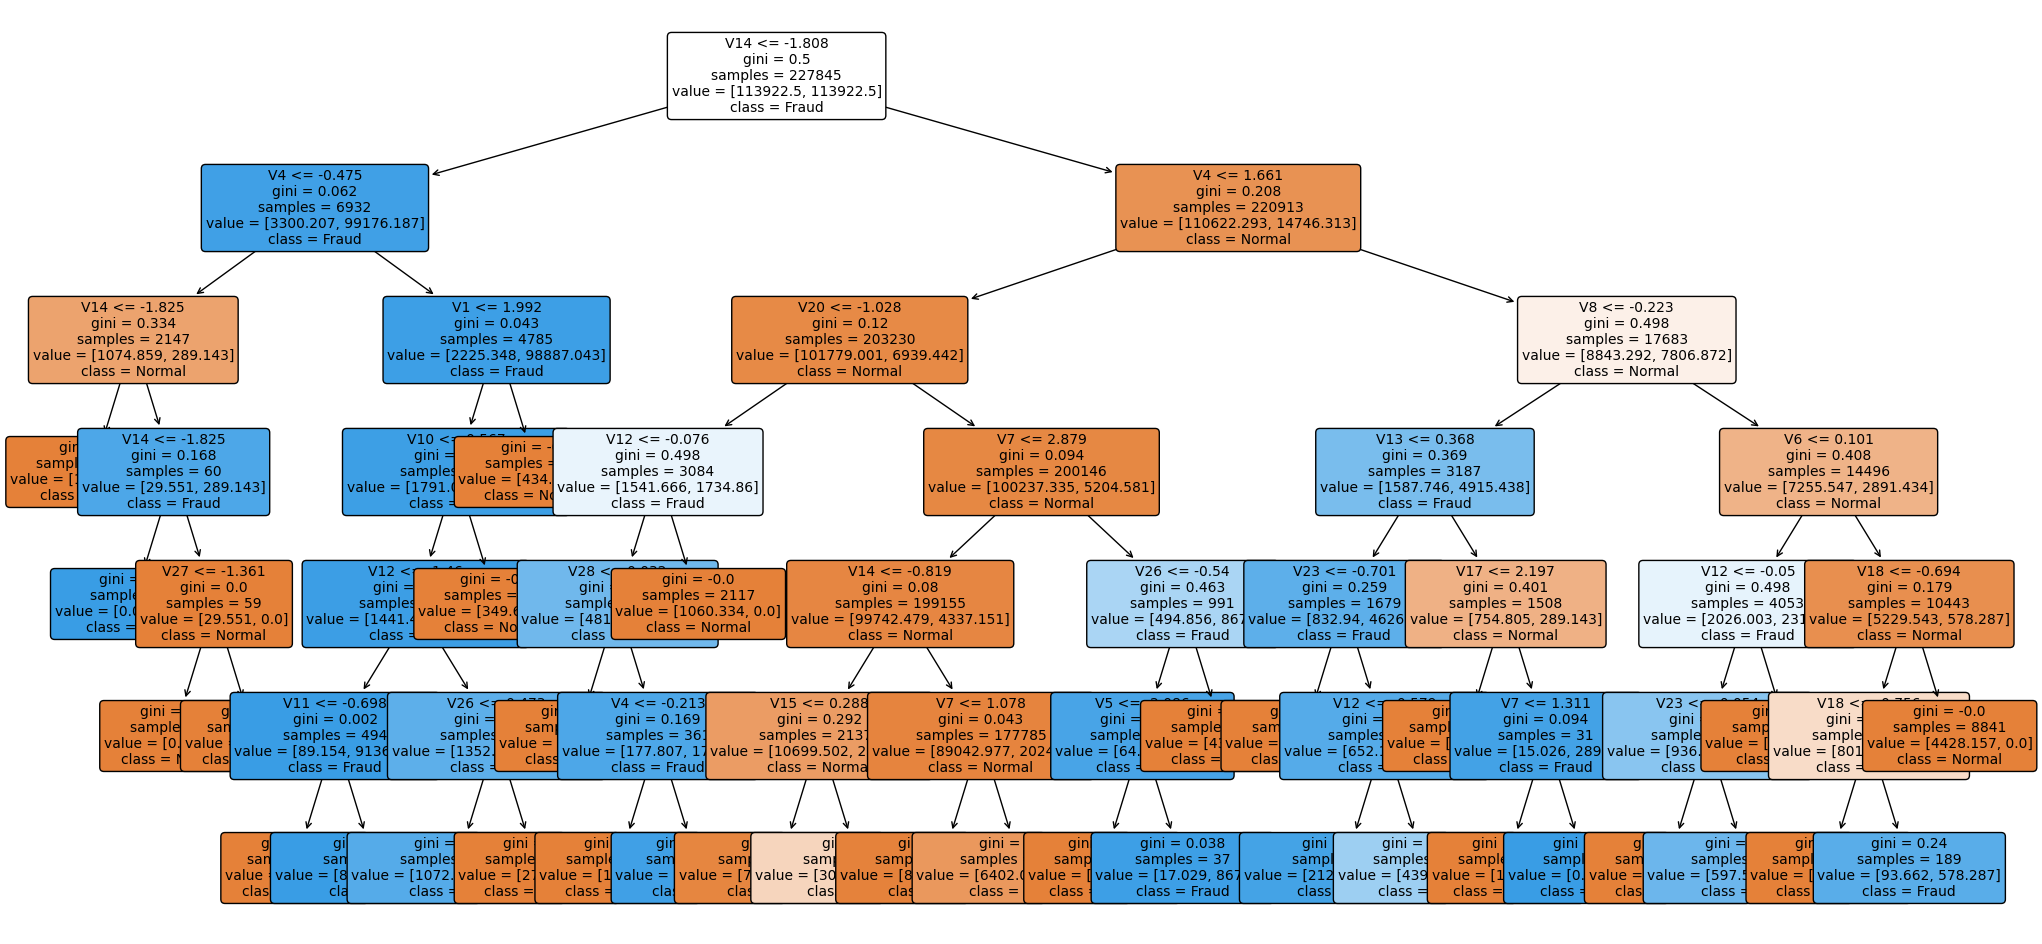

In [8]:
import matplotlib.pyplot as plt
from sklearn import tree

best_fraud_tree = DecisionTreeClassifier(max_depth=6, class_weight='balanced', random_state=42)
best_fraud_tree.fit(X_train, y_train)

plt.figure(figsize=(25,12))
tree.plot_tree(best_fraud_tree, 
               feature_names=list(X.columns), 
               class_names=['Normal', 'Fraud'], 
               filled=True, 
               rounded=True,
               fontsize=10)
plt.show()

In [9]:
from sklearn.tree import export_text

# Generate the text rules for your best fraud model
fraud_rules = export_text(best_fraud_tree, feature_names=list(X.columns))

print("--- Credit Card Fraud Decision Rules ---")
print(fraud_rules)

--- Credit Card Fraud Decision Rules ---
|--- V14 <= -1.81
|   |--- V4 <= -0.48
|   |   |--- V14 <= -1.83
|   |   |   |--- class: 0
|   |   |--- V14 >  -1.83
|   |   |   |--- V14 <= -1.82
|   |   |   |   |--- class: 1
|   |   |   |--- V14 >  -1.82
|   |   |   |   |--- V27 <= -1.36
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- V27 >  -1.36
|   |   |   |   |   |--- class: 0
|   |--- V4 >  -0.48
|   |   |--- V1 <= 1.99
|   |   |   |--- V10 <= 0.57
|   |   |   |   |--- V12 <= -1.46
|   |   |   |   |   |--- V11 <= -0.70
|   |   |   |   |   |   |--- class: 0
|   |   |   |   |   |--- V11 >  -0.70
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |--- V12 >  -1.46
|   |   |   |   |   |--- V26 <= 0.47
|   |   |   |   |   |   |--- class: 1
|   |   |   |   |   |--- V26 >  0.47
|   |   |   |   |   |   |--- class: 0
|   |   |   |--- V10 >  0.57
|   |   |   |   |--- class: 0
|   |   |--- V1 >  1.99
|   |   |   |--- class: 0
|--- V14 >  -1.81
|   |--- V4 <= 1.66
|   |   |--- V20 <= -1.03